# MATH-500 Few-Shot Prompting Benchmark
This notebook benchmarks various `Qwen2.5` model configurations on the **MATH-500** dataset, measuring the impact of zero-shot vs. 10-shot prompting techniques on final accuracy.

In [1]:
pip install -q transformers datasets accelerate torch math-verify matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
print(torch.__version__)

2.13.0+cu129


In [3]:
import torch

# Check if CUDA is available and print device information
if torch.cuda.is_available():
    print("GPU Device Name:", torch.cuda.get_device_name(0))
    print("Memory Allocated:", round(torch.cuda.memory_allocated(0)/1024**3,1), "GB")
    print("Memory Cached:   ", round(torch.cuda.memory_reserved(0)/1024**3,1), "GB")
    print("\n--- NVIDIA-SMI Command Output ---")
    !nvidia-smi
else:
    print("No GPU detected in this runtime.")

GPU Device Name: NVIDIA A100 80GB PCIe
Memory Allocated: 0.0 GB
Memory Cached:    0.0 GB

--- NVIDIA-SMI Command Output ---
Sun Nov  8 20:39:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.91.07              Driver Version: 595.91.07      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          On  |   00000000:00:0D.0 Off |                    0 |
| N/A   48C    P0             51W /  300W |       4MiB /  81920MiB |      0%      Default |
|               

## 1. Environment Setup & Configuration
In this section, we import the necessary libraries, ensure complete reproducibility by setting seeds, and configure hardware-optimized batch sizes per model size to maximize performance on our GPU runtime.

In [4]:
import gc
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from datasets import load_dataset, Dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline
from tqdm.auto import tqdm

# Ensure reproducibility
random.seed(21)
torch.manual_seed(42)

# Configure to test the official base variants of the models
models_to_test = [
    'Qwen/Qwen2.5-7B',
    'Qwen/Qwen2.5-3B',
    'Qwen/Qwen2.5-1.5B'
]

# Define optimal batch sizes per model to maximize A100 80GB VRAM usage
model_batch_sizes = {
    'Qwen/Qwen2.5-7B': 32,
    'Qwen/Qwen2.5-3B': 64,
    'Qwen/Qwen2.5-1.5B': 64
}

# Structure to store accuracy metrics for zero-shot and 10-shot benchmark configurations
results = {m: {'zero_shot': 0, '10_shot': 0} for m in models_to_test}

## 2. Dataset Loading & Few-Shot Splitting
We load the **MATH-500** dataset from HuggingFace. Then, we partition the dataset by selecting 10 random problems as few-shot examples and reserving the remaining problems for our main evaluation test set. Finally, we dynamically build the few-shot context prompt strings for our 10-shot test configuration.

In [5]:
print("Loading MATH-500 dataset...")
# Load MATH-500
math500_dataset = load_dataset("HuggingFaceH4/MATH-500")
full_test_ds = math500_dataset['test']

# Shuffle indices to ensure random selection
indices = list(range(len(full_test_ds)))
random.shuffle(indices)

print("Partitioning into 10 entirely random few-shot examples and 400 evaluation examples...")
few_shot_indices = indices[:10]
eval_indices = indices[10:490]  # Take exactly 200 examples for evaluation

few_shot_examples = [full_test_ds[idx] for idx in few_shot_indices]
eval_examples = [full_test_ds[idx] for idx in eval_indices]

print(f"Selected {len(few_shot_examples)} random few-shot examples.")
print(f"Selected {len(eval_examples)} problems for evaluation.")

# Convert eval_examples back to a HuggingFace Dataset so .select() works in the inference cell
test_ds = Dataset.from_list(eval_examples)

# System instruction to improve extraction robustness
instruction = "Solve the following mathematical problem step by step. Show your reasoning clearly, and put your final answer inside a \boxed{...} block.\n\n"

# Construct prompt components for 10-shot
few_shot_10_prompt = ""
for ex in few_shot_examples:
    few_shot_10_prompt += f"Problem:\n{ex['problem']}\n\nSolution:\n{ex['solution']}\n\n"

Loading MATH-500 dataset...


Partitioning into 10 entirely random few-shot examples and 400 evaluation examples...
Selected 10 random few-shot examples.
Selected 480 problems for evaluation.


## 3. Answer Extraction and Equivalence Logic
To accurately verify mathematical solutions (such as algebraic expressions or fractions), we define robust parsing functions. We extract the LaTeX answer from the `\boxed{...}` block and utilize the `math_verify` library to test mathematical equivalence beyond simple string equality matching.

In [6]:
from math_verify import parse, verify

def extract_boxed_answer(text):
    # Robustly extract the last \boxed{...} content, handling nested braces
    idx = text.find("\\boxed{")
    if idx == -1:
        return None

    start = idx + len("\\boxed{")
    brace_count = 1

    for i in range(start, len(text)):
        if text[i] == '{':
            brace_count += 1
        elif text[i] == '}':
            brace_count -= 1

        if brace_count == 0:
            return text[start:i]
    return None

def check_equivalence(pred_str, gt_str):
    if not pred_str or not gt_str:
        return False
    try:
        # Parse math expressions and use math_verify to check mathematical equivalence
        pred_parsed = parse(pred_str)
        gt_parsed = parse(gt_str)
        return verify(pred_parsed, gt_parsed)
    except Exception:
        # Fallback to strict string comparison if parsing fails
        return pred_str.strip() == gt_str.strip()

## 4. Benchmark Inference and Evaluation Loop
Here we run our main benchmarking loop across all models. For each model size, we run batch generation over two distinct configurations: **Zero-shot and 10-shot**. Outputs are processed, verified against the ground truth labels, and cleaned up to prevent VRAM memory overflows.

In [7]:
def build_chat_prompts(tokenizer, system_instruction, few_shot_items, evaluation_dataset):
    """
    Formats prompts for base models as flat structured text string completions
    instead of role-based Chat Templates.
    """
    formatted_prompts = []

    for item in evaluation_dataset:
        prompt_parts = []

        # 1. Add System Instruction
        if system_instruction:
            prompt_parts.append(system_instruction)

        # 2. Add Few-Shot Exemplars
        for ex in few_shot_items:
            prompt_parts.append(f"Problem:\n{ex['problem']}\n\nSolution:\n{ex['solution']}\n\n")

        # 3. Add the active evaluation problem
        prompt_parts.append(f"Problem:\n{item['problem']}\n\nSolution:\n")

        prompt_str = "".join(prompt_parts)
        formatted_prompts.append(prompt_str)

    return formatted_prompts

In [8]:
import json

total = len(test_ds)
print("Starting multi-model evaluation...")

for model_name in models_to_test:
    print(f"\n{'='*40}\nEvaluating {model_name}\n{'='*40}")

    # 1. Load Tokenizer & Model
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        dtype=torch.bfloat16,
        device_map="auto"
    )

    # Dynamically build chat-templated prompts using the model's tokenizer
    print(f"Preparing chat-templated prompts for {model_name}...")
    prompts_dict = {
        'zero_shot': build_chat_prompts(tokenizer, instruction, [], test_ds),
        '10_shot': build_chat_prompts(tokenizer, instruction, few_shot_examples, test_ds)
    }

    # Get optimized batch size for this specific model
    current_batch_size = model_batch_sizes.get(model_name, 16)
    print(f"Using optimized batch size: {current_batch_size}")

    generation_results = {}

    # 2. Loop through all evaluation modes
    for mode, prompts in prompts_dict.items():
        print(f"Running {mode} Inference...")
        generated_texts = []
        for i in tqdm(range(0, len(prompts), current_batch_size), desc=mode):
            batch = prompts[i:i + current_batch_size]
            inputs = tokenizer(batch, return_tensors="pt", padding=True, truncation=False).to(model.device)
            with torch.no_grad():
                outputs = model.generate(
                    **inputs, max_new_tokens=2048, do_sample=False,
                    pad_token_id=tokenizer.pad_token_id, tokenizer=tokenizer,
                    stop_strings=["Problem:", "\nProblem:"]
                )
            gen_tokens = outputs[:, inputs.input_ids.shape[1]:]
            decoded = tokenizer.batch_decode(gen_tokens, skip_special_tokens=True)
            generated_texts.extend(decoded)
        generation_results[mode] = generated_texts

    # 3. Evaluation using math_verify
    detailed_logs = []
    correct_counts = {mode: 0 for mode in prompts_dict.keys()}

    for i in range(total):
        gt = test_ds[i]['answer'].strip()

        extracted = {}
        correctness = {}
        for mode in prompts_dict.keys():
            extracted[mode] = extract_boxed_answer(generation_results[mode][i])
            correctness[mode] = check_equivalence(extracted[mode], gt)
            if correctness[mode]:
                correct_counts[mode] += 1

        log_item = {
            "problem": test_ds[i]['problem'],
            "ground_truth": gt
        }
        for mode in prompts_dict.keys():
            log_item[f"{mode}_generated"] = generation_results[mode][i]
            log_item[f"{mode}_extracted"] = extracted[mode]
            log_item[f"{mode}_correct"] = correctness[mode]
        detailed_logs.append(log_item)

    for mode in prompts_dict.keys():
        results[model_name][mode] = correct_counts[mode] / total * 100

    results[model_name]['detailed'] = detailed_logs

    print(f"{model_name} -> Zero-Shot: {results[model_name]['zero_shot']:.2f}% | 10-Shot: {results[model_name]['10_shot']:.2f}%")

    # 4. Memory Cleanup
    del model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()

# Save all compiled results to a JSON file
with open("math500_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("\nAll models evaluated. Detailed results saved to 'math500_results.json'.")

Starting multi-model evaluation...

Evaluating Qwen/Qwen2.5-7B


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Preparing chat-templated prompts for Qwen/Qwen2.5-7B...
Using optimized batch size: 32
Running zero_shot Inference...


zero_shot:   0%|          | 0/15 [00:00<?, ?it/s]

[W1108 20:41:56.191724774 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 484442112 bytes (free: 425656320, total: 85094825984).


Running 10_shot Inference...


... (11 outputs left out)

zero_shot:   0%|          | 0/8 [00:00<?, ?it/s]

Running 10_shot Inference...


10_shot:   0%|          | 0/8 [00:00<?, ?it/s]

Qwen/Qwen2.5-1.5B -> Zero-Shot: 25.00% | 10-Shot: 26.25%

All models evaluated. Detailed results saved to 'math500_results.json'.


## 5. Performance Visualization
This section visualizes our model benchmarking results. We construct a multi-bar chart to visually compare accuracies across different shot counts and model scales.

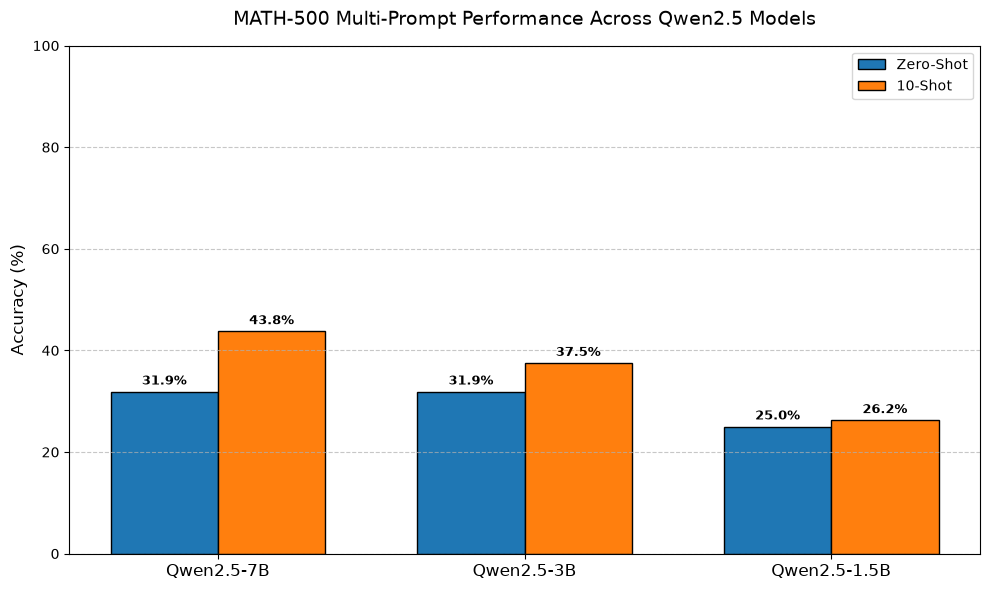

In [9]:
# Plotting the comparative results across zero-shot and 10-shot configurations
x = np.arange(len(models_to_test))  # the label locations
width = 0.35  # adjusted width to fit 2 bars

fig, ax = plt.subplots(figsize=(10, 6))

rects0 = ax.bar(x - width/2, [results[m]['zero_shot'] for m in models_to_test], width, label='Zero-Shot', color='#1f77b4', edgecolor='black')
rects10 = ax.bar(x + width/2, [results[m]['10_shot'] for m in models_to_test], width, label='10-Shot', color='#ff7f0e', edgecolor='black')

# Add labels, title, and legends
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('MATH-500 Multi-Prompt Performance Across Qwen2.5 Models', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels([m.split('/')[-1] for m in models_to_test], fontsize=12)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects0)
autolabel(rects10)

plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
fig.tight_layout()
plt.show()

## 6. Performance Summary Table
Finally, we compile all evaluation metrics into a single Pandas DataFrame to review the finalized benchmark accuracies side-by-side.

In [10]:
import pandas as pd

# Prepare summary data from results dict supporting zero-shot and 10-shot with 1 decimal accuracy
summary_data = []
for model, metrics in results.items():
    summary_data.append({
        'Model': model.split('/')[-1],
        'Zero-Shot (%)': f"{metrics.get('zero_shot', 0):.1f}%",
        '10-Shot (%)': f"{metrics.get('10_shot', 0):.1f}%"
    })

summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Model,Zero-Shot (%),10-Shot (%)
0,Qwen2.5-7B,31.9%,43.8%
1,Qwen2.5-3B,31.9%,37.5%
2,Qwen2.5-1.5B,25.0%,26.2%
